# Task 1: Build an overfitting model

## real_or_fake.ipynb
## Download the data & build the model
### The objective in this task is to design a convolutional neural network to overfit the dataset.

Adam Oakes

## Library Imports


In [29]:
import keras, kagglehub, pathlib
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from keras import layers
from keras.utils import image_dataset_from_directory

## Get the dataset from Kaggle

### CIFAKE: Real and AI-Generated Synthetic Images

#### https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images

##### Dataset details

The dataset contains two classes - REAL and FAKE.

For REAL, we collected the images from Krizhevsky & Hinton's CIFAR-10 dataset

For the FAKE images, we generated the equivalent of CIFAR-10 with Stable Diffusion version 1.4

There are 100,000 images for training (50k per class) and 20,000 for testing (10k per class)

In [ ]:
# Download latest version
path = kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images")

print("Path to dataset files:", path)

dir = pathlib.Path(path)

## Using image_dataset_from_directory to read images from directories

In [20]:
image_size = (180, 180)
batch_size = 64
EPOCHS = 20

train_dataset = image_dataset_from_directory(
    dir / "train", image_size=image_size, batch_size=batch_size, label_mode="binary"
)

Found 100000 files belonging to 2 classes.


## Choosing a measure of success

For this classification problem, the classes are balanced & equally likely. It is for this reason that I am choosing accuracy.

## Instantiating a small ConvNet for REAL vs FAKE classification

In [21]:
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model1 = keras.Model(inputs=inputs, outputs=outputs)

model1.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

history1 = model1.fit(
    train_dataset,
    epochs=EPOCHS,
)

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 52s 31ms/step - accuracy: 0.8196 - loss: 0.3953
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 48s 31ms/step - accuracy: 0.9036 - loss: 0.2384
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 51s 33ms/step - accuracy: 0.9194 - loss: 0.2058
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 50s 32ms/step - accuracy: 0.9282 - loss: 0.1828
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 47s 30ms/step - accuracy: 0.9353 - loss: 0.1666
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 48s 31ms/step - accuracy: 0.9399 - loss: 0.1530
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 48s 31ms/step - accuracy: 0.9439 - loss: 0.1431
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 52s 33ms/step - accuracy: 0.9492 - loss: 0.1298
Epoch 9/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 49s 32ms/step - accuracy: 0.9527 - loss: 0.1209
Epoch 10/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 49s 31ms/step - accuracy: 0.9581 - loss: 0.1088
Epoch 11/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 47s 30ms/step - accuracy: 0.9623 - loss: 0.0991
Epoch 12

##  Please study how the accuracy changes when the hyperparameters, such as, the number of filters, layers, etc., are increased and decreased.

### Decrease the amount filters (Model2)

In [22]:
#decrease filters
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=8, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=16, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model2 = keras.Model(inputs=inputs, outputs=outputs)

model2.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

history2 = model2.fit(
    train_dataset,
    epochs=EPOCHS,
)

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.7595 - loss: 0.4943
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8340 - loss: 0.3814
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.8738 - loss: 0.3077
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.8851 - loss: 0.2841
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.8932 - loss: 0.2659
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.8977 - loss: 0.2560
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9037 - loss: 0.2438
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9047 - loss: 0.2390
Epoch 9/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9089 - loss: 0.2319
Epoch 10/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9115 - loss: 0.2244
Epoch 11/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9136 - loss: 0.2180
Epoch 12

### Increase the amount filters (Model3)

In [23]:
#increase filters
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=1024, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model3 = keras.Model(inputs=inputs, outputs=outputs)

model3.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

history3 = model3.fit(
    train_dataset,
    epochs=EPOCHS,
)

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 249s 151ms/step - accuracy: 0.7934 - loss: 0.4399
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 227s 145ms/step - accuracy: 0.8881 - loss: 0.2744
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 213s 136ms/step - accuracy: 0.9090 - loss: 0.2290
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 220s 141ms/step - accuracy: 0.9196 - loss: 0.2045
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 225s 144ms/step - accuracy: 0.9242 - loss: 0.1927
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 217s 139ms/step - accuracy: 0.9283 - loss: 0.1839
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 223s 143ms/step - accuracy: 0.9322 - loss: 0.1762
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 221s 141ms/step - accuracy: 0.9348 - loss: 0.1691
Epoch 9/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 221s 142ms/step - accuracy: 0.9369 - loss: 0.1620
Epoch 10/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 222s 142ms/step - accuracy: 0.9411 - loss: 0.1559
Epoch 11/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 225s 144ms/step - accuracy: 0.9413 -

### Decrease the amount layers (Model4)

In [24]:
#decrease layers

inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model4 = keras.Model(inputs=inputs, outputs=outputs)

model4.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

history4 = model4.fit(
    train_dataset,
    epochs=EPOCHS,
)

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 53s 32ms/step - accuracy: 0.7416 - loss: 0.5150
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 45s 29ms/step - accuracy: 0.8209 - loss: 0.4081
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 44s 28ms/step - accuracy: 0.8490 - loss: 0.3632
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 47s 30ms/step - accuracy: 0.8598 - loss: 0.3378
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - accuracy: 0.8685 - loss: 0.3219
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 42s 27ms/step - accuracy: 0.8748 - loss: 0.3083
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 47s 30ms/step - accuracy: 0.8819 - loss: 0.2921
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 46s 30ms/step - accuracy: 0.8894 - loss: 0.2756
Epoch 9/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 42s 27ms/step - accuracy: 0.8953 - loss: 0.2633
Epoch 10/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 42s 27ms/step - accuracy: 0.8993 - loss: 0.2520
Epoch 11/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 42s 27ms/step - accuracy: 0.9038 - loss: 0.2438
Epoch 12

### Increase the amount layers (Model5)

In [25]:
#increase layer count

inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model5 = keras.Model(inputs=inputs, outputs=outputs)

model5.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

history5 = model5.fit(
    train_dataset,
    epochs=EPOCHS,
)

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 50s 28ms/step - accuracy: 0.8277 - loss: 0.3807
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 39s 25ms/step - accuracy: 0.8988 - loss: 0.2485
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 34s 22ms/step - accuracy: 0.9148 - loss: 0.2108
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accuracy: 0.9275 - loss: 0.1849
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 42s 27ms/step - accuracy: 0.9370 - loss: 0.1605
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 35s 23ms/step - accuracy: 0.9455 - loss: 0.1397
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 40s 25ms/step - accuracy: 0.9535 - loss: 0.1200
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.9597 - loss: 0.1042
Epoch 9/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 40s 26ms/step - accuracy: 0.9665 - loss: 0.0867
Epoch 10/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.9702 - loss: 0.0768
Epoch 11/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 39s 25ms/step - accuracy: 0.9751 - loss: 0.0657
Epoch 12

## Compare the models

### How performance metrics (accuracy, precision, recall, etc.) change when:
- The number of filters increases/decreases
- The number of layers increases/decreases

In [26]:
print(history1.history["accuracy"][-1])
print(history2.history["accuracy"][-1])
print(history3.history["accuracy"][-1])
print(history4.history["accuracy"][-1])
print(history5.history["accuracy"][-1])

0.9865999817848206
0.92808997631073
0.9596999883651733
0.9223099946975708
0.9888299703598022


In [28]:
print(model1.count_params())
print(model2.count_params())
print(model3.count_params())
print(model4.count_params())
print(model5.count_params())

1569089
24593
6199553
93377
1578337


#### Layers:
    - small - accuracy: 0.92
    - medium - accuracy: 0.99
    - large - accuracy: 0.99

### Filters:
    - small -  accuracy: 0.93
    - medium - accuracy: 0.99
    - large -  accuracy: 0.96

Making the model bigger had a general effect of improving our accuracy.

### Plot the training loss

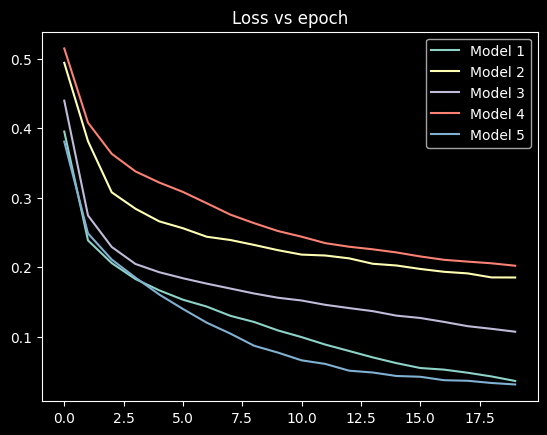

In [30]:
plt.title("Loss vs epoch")
plt.plot(history1.history["loss"], label="Model 1")
plt.plot(history2.history["loss"], label="Model 2")
plt.plot(history3.history["loss"], label="Model 3")
plt.plot(history4.history["loss"], label="Model 4")
plt.plot(history5.history["loss"], label="Model 5")

plt.legend()

### Plot the training accuracy

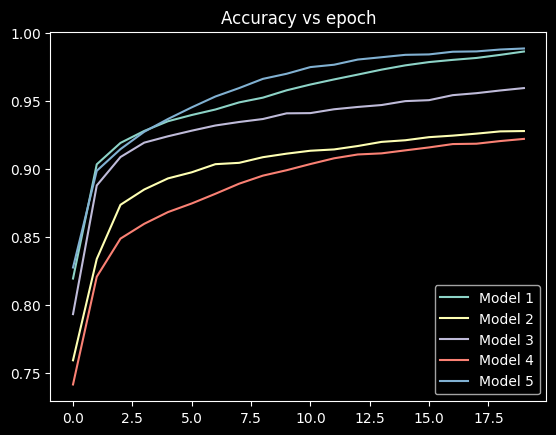

In [31]:
plt.title("Accuracy vs epoch")
plt.plot(history1.history["accuracy"], label="Model 1")
plt.plot(history2.history["accuracy"], label="Model 2")
plt.plot(history3.history["accuracy"], label="Model 3")
plt.plot(history4.history["accuracy"], label="Model 4")
plt.plot(history5.history["accuracy"], label="Model 5")

plt.legend()
plt.show()

## Graduate Student Requirement

If the output is provided as an additional input channel, what is the smallest architecture (minimum number of layers and filters) needed to overfit the data?

In [32]:
# -----------------------------------------------------------------------------
# Generated by  Claude (Opus 5, model ID: claude-opus-5)
# by Anthropic, via Claude Code, on 2026-10-28.
# -----------------------------------------------------------------------------

def add_channel(images, labels):
    # images: (batch, 180, 180, 3) float32
    extra = labels[:, :, None, None] * tf.ones_like(images[..., :1])
    return tf.concat([images, extra], axis=-1), labels

ds = train_dataset.map(add_channel, num_parallel_calls=tf.data.AUTOTUNE)

In [33]:
ds.element_spec

(TensorSpec(shape=(None, 180, 180, 4), dtype=tf.float32, name=None),
 TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))

In [34]:
inputs = keras.Input(shape=(180, 180, 4))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=2, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model_with_output = keras.Model(inputs=inputs, outputs=outputs)

model_with_output.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)
history_w_output = model_with_output.fit(
    ds,
    epochs=4,
    batch_size=64
)

Epoch 1/4
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.6429 - loss: 0.6662
Epoch 2/4
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.8719 - loss: 0.5869
Epoch 3/4
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.9886 - loss: 0.4779
Epoch 4/4
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.9998 - loss: 0.3612
